# 03 - Remote Job Market Analysis (all fields + IT deep dive)

## Objective
**Part A - The market:** which fields are the most requested? How do seniority and salary differ between fields?
**Part B - IT deep dive:** which IT fields are most requested, and which skills does each one need?

## Rules
- Every result shows the **number of jobs (n)**. Small groups are marked with `*` and should not be over-interpreted.
- The data comes from **remote** job boards (RemoteOK and Remotive): it describes the remote job market, not the whole job market.
- Fields and seniority are guessed from the job category and title, so they are approximate.
- IT skills are analysed for IT jobs only (the skill list is technical).

In [21]:
import sqlite3
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.patches import Patch

CLEAN_PATH = "../data/clean/jobs_clean.csv"
IMAGES = Path("../images")
IMAGES.mkdir(exist_ok=True)

MIN_N = 10                      # groups with fewer jobs are marked with *
MIN_SALARY_N = 5                # minimum salaries needed to show a salary figure
ACCENT, ACCENT2 = "#3B4CCA", "#0E9F8E"
LEVELS = ["Intern", "Junior", "Mid", "Senior+"]
LEVEL_COLORS = {"Intern": "#c9cdea", "Junior": "#7A86E8", "Mid": "#3B4CCA", "Senior+": "#14182b"}
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titleweight": "bold", "axes.titlesize": 13})

SKILL_GROUPS = {
    "Languages": ["python", "javascript", "typescript", "java", "csharp_dotnet", "cpp", "go", "rust",
                  "php", "ruby", "kotlin_swift", "sql"],
    "Frameworks": ["react", "angular", "vue", "nodejs", "django_flask", "spring"],
    "Cloud & DevOps": ["aws", "azure", "gcp", "docker", "kubernetes", "terraform_iac", "ci_cd", "linux", "git"],
    "Data & Databases": ["mongodb_nosql", "redis", "kafka_queues", "spark_hadoop", "cloud_warehouse",
                         "power_bi", "tableau", "excel"],
    "AI": ["machine_learning", "deep_learning", "llm_genai"],
    "Practices": ["rest_api", "microservices", "testing", "agile", "security_practices"],
}
GROUP_OF = {s: g for g, skills in SKILL_GROUPS.items() for s in skills}
GROUP_COLORS = {"Languages": "#3B4CCA", "Frameworks": "#7A86E8", "Cloud & DevOps": "#0E9F8E",
                "Data & Databases": "#E0A030", "AI": "#C2185B", "Practices": "#8A8FA8", "Other": "#bbbbbb"}
SKILL_LABELS = {"csharp_dotnet": "C# / .NET", "cpp": "C++", "go": "Go", "kotlin_swift": "Kotlin / Swift",
                "sql": "SQL", "nodejs": "Node.js", "django_flask": "Django / Flask", "aws": "AWS", "gcp": "GCP",
                "ci_cd": "CI/CD", "terraform_iac": "Terraform / IaC", "mongodb_nosql": "MongoDB / NoSQL",
                "kafka_queues": "Kafka / Queues", "spark_hadoop": "Spark / Hadoop", "cloud_warehouse": "Snowflake / BigQuery",
                "power_bi": "Power BI", "llm_genai": "LLM / GenAI", "rest_api": "REST / APIs",
                "security_practices": "Security practices", "php": "PHP", "javascript": "JavaScript",
                "typescript": "TypeScript", "react": "React", "git": "Git", "linux": "Linux"}

skill_of = lambda col: col[4:]
label = lambda col: SKILL_LABELS.get(skill_of(col), skill_of(col).replace("_", " ").title())
group = lambda col: GROUP_OF.get(skill_of(col), "Other")

def save(fig, name):
    fig.savefig(IMAGES / f"{name}.png", dpi=150, bbox_inches="tight")

df = pd.read_csv(CLEAN_PATH, parse_dates=["date", "posted_date"])
skill_cols = [c for c in df.columns if c.startswith("has_")]

known = df[df["market_field"] != "Other"]            # jobs whose field we could identify
it_jobs = df[df["is_it_job"]].copy()
N_ALL, N_KNOWN, N_IT = len(df), len(known), len(it_jobs)
print(f"All jobs: {N_ALL} | field identified: {N_KNOWN} | IT jobs: {N_IT}")
if N_ALL < 500:
    print("NOTE: fewer than 500 jobs. Small fields will have too few jobs for reliable percentages.")

All jobs: 117 | field identified: 99 | IT jobs: 68
NOTE: fewer than 500 jobs. Small fields will have too few jobs for reliable percentages.


## Helper functions
The same three charts are used for the whole market (Part A) and for the IT fields (Part B).

In [22]:
def plot_counts(counts, title, fname, color=ACCENT):
    c = counts[::-1]
    fig, ax = plt.subplots(figsize=(8, 0.9 + 0.45 * len(c)))
    bars = ax.barh(c.index, c.values, color=color)
    ax.bar_label(bars, labels=[f"{v}  ({v / counts.sum() * 100:.0f}%)" for v in c.values], padding=3)
    ax.set_xlim(0, c.max() * 1.28)
    ax.set_xlabel("number of jobs")
    ax.set_title(title)
    save(fig, fname)
    plt.show()


def plot_seniority(data, col, order, title, fname):
    counts = data[col].value_counts().reindex(order)
    levels = [l for l in LEVELS if l in data["seniority"].unique()]
    ct = pd.crosstab(data[col], data["seniority"]).reindex(index=order, columns=levels, fill_value=0)
    pct = ct.div(ct.sum(axis=1), axis=0) * 100
    fig, ax = plt.subplots(figsize=(9, 0.9 + 0.5 * len(order)))
    left = np.zeros(len(order))
    for lvl in levels:
        ax.barh(range(len(order)), pct[lvl].values, left=left, color=LEVEL_COLORS[lvl], label=lvl)
        for i, v in enumerate(pct[lvl].values):
            if v >= 8:
                ax.text(left[i] + v / 2, i, f"{v:.0f}", ha="center", va="center",
                        color="white" if lvl != "Intern" else "black", fontsize=8)
        left += pct[lvl].values
    ax.set_yticks(range(len(order)), [f"{g} (n={counts[g]}){'*' if counts[g] < MIN_N else ''}" for g in order])
    ax.invert_yaxis()
    ax.set_xlim(0, 100)
    ax.set_xlabel("% of jobs in the field")
    ax.set_title(title)
    ax.legend(ncol=len(levels), loc="upper center", bbox_to_anchor=(0.5, -0.15), frameon=False)
    save(fig, fname)
    plt.show()
    return ct


def salary_summary(data, col, title, fname):
    sal = data[data["salary_available"]]
    print(f"{len(sal)} of {len(data)} jobs show a salary ({len(sal) / max(len(data), 1):.0%})")
    table = sal.groupby(col)["salary_mid"].agg(jobs="count", median="median", min="min", max="max")
    table["note"] = np.where(table["jobs"] < MIN_SALARY_N, "* too few salaries", "")
    table = table.sort_values("median", ascending=False).round(0)
    enough = table[table["jobs"] >= MIN_SALARY_N]["median"][::-1]
    if len(enough):
        fig, ax = plt.subplots(figsize=(8, 0.9 + 0.45 * len(enough)))
        bars = ax.barh(enough.index, enough.values, color=ACCENT2)
        ax.bar_label(bars, labels=[f"{v / 1000:.0f}k" for v in enough.values], padding=3)
        ax.set_xlim(0, enough.max() * 1.15)
        ax.set_xlabel("median salary (USD / year)")
        ax.set_title(title)
        save(fig, fname)
        plt.show()
    else:
        print("No group has enough salaries yet for a chart. Collect more data.")
    return table

# Part A - The remote job market

## A0. Overview

In [23]:
overview = {
    "Jobs": N_ALL,
    "Field identified": f"{N_KNOWN} ({N_KNOWN / N_ALL:.0%})",
    "IT jobs": f"{N_IT} ({N_IT / N_ALL:.0%})",
    "Sources": ", ".join(sorted(df["source"].dropna().unique())),
    "Period": f'{df["posted_date"].min():%Y-%m-%d} to {df["posted_date"].max():%Y-%m-%d}',
    "Jobs showing a salary": f'{df["salary_available"].sum()} ({df["salary_available"].mean():.0%})',
}
pd.Series(overview, name="value").to_frame()

,value
Jobs,117
Field identified,99 (85%)
IT jobs,68 (58%)
Sources,"remoteok, remotive"
Period,2026-07-30 to 2026-10-05
Jobs showing a salary,22 (19%)


## A1. Which fields are the most requested?
Jobs whose field could not be identified (`Other`) are left out of the chart.

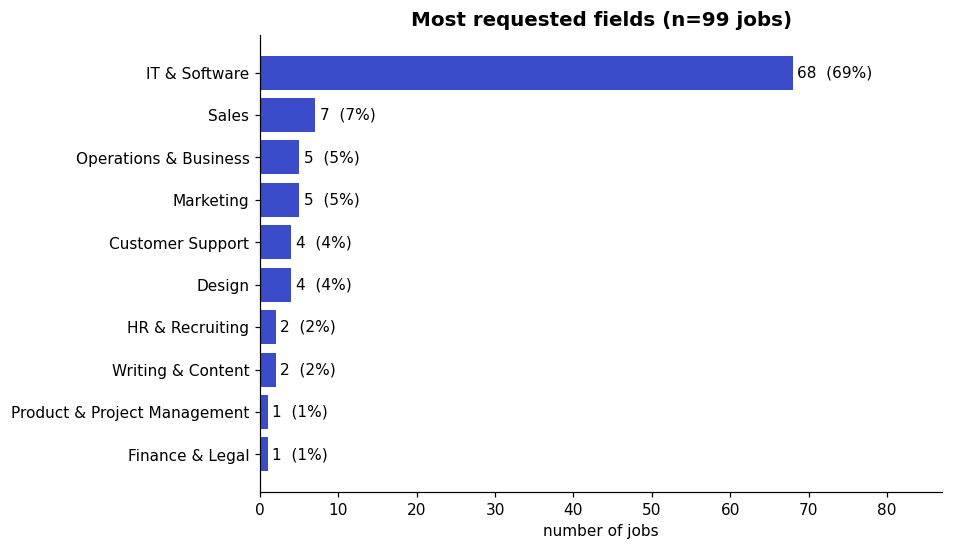

,jobs,% of identified jobs
market_field,,
IT & Software,68,68.7
Sales,7,7.1
Operations & Business,5,5.1
Marketing,5,5.1
Customer Support,4,4.0
Design,4,4.0
HR & Recruiting,2,2.0
Writing & Content,2,2.0
Product & Project Management,1,1.0


In [24]:
market_counts = known["market_field"].value_counts()
plot_counts(market_counts, f"Most requested fields (n={N_KNOWN} jobs)", "A1_market_fields")
pd.DataFrame({"jobs": market_counts, "% of identified jobs": (market_counts / N_KNOWN * 100).round(1)})

## A2. Seniority by field
Share of Junior / Mid / Senior+ jobs in each field. `Mid` means the title has no level.
Look at the **Junior** share: it shows how open each field is to beginners.

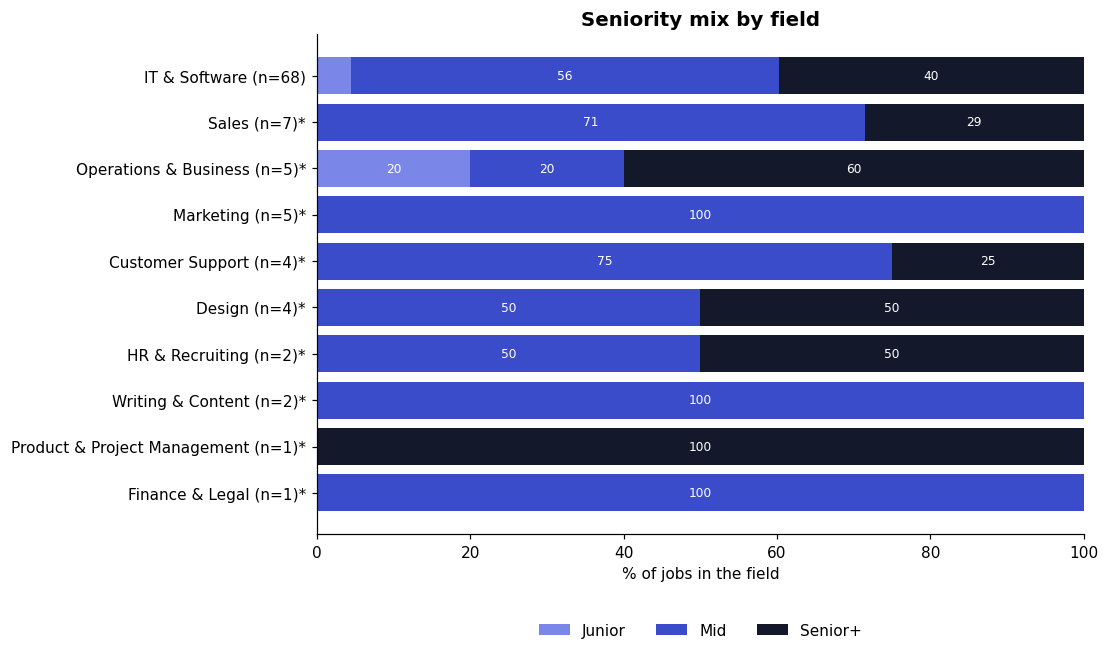

,jobs,% Junior
market_field,,
Operations & Business,5,20.0
IT & Software,68,4.4
Sales,7,0.0
Marketing,5,0.0
Customer Support,4,0.0
Design,4,0.0
HR & Recruiting,2,0.0
Writing & Content,2,0.0
Product & Project Management,1,0.0


In [25]:
ct_market = plot_seniority(known, "market_field", market_counts.index.tolist(),
                           "Seniority mix by field", "A2_seniority_by_field")
junior_share = (ct_market["Junior"] / ct_market.sum(axis=1) * 100).round(1) if "Junior" in ct_market else None
pd.DataFrame({"jobs": ct_market.sum(axis=1), "% Junior": junior_share}).sort_values("% Junior", ascending=False)

## A3. Salary by field
Only jobs that show a salary are used (usually a small share). Amounts are yearly, mostly USD.
The **median** is used because a few very high salaries distort the average.

18 of 99 jobs show a salary (18%)


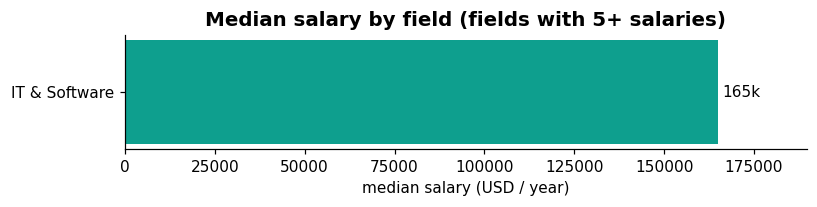

,jobs,median,min,max,note
market_field,,,,,
Marketing,1,202500.0,202500.0,202500.0,* too few salaries
IT & Software,11,165000.0,15000.0,320000.0,
Operations & Business,2,165000.0,70000.0,260000.0,* too few salaries
HR & Recruiting,1,75000.0,75000.0,75000.0,* too few salaries
Sales,2,30000.0,30000.0,30000.0,* too few salaries
Writing & Content,1,27500.0,27500.0,27500.0,* too few salaries


In [26]:
salary_summary(known, "market_field", f"Median salary by field (fields with {MIN_SALARY_N}+ salaries)", "A3_salary_by_field")

## A4. Postings over time
*Caution:* the sources list only currently active jobs, so older weeks look smaller than they really were.
Use this to describe the collection window, not a market trend.

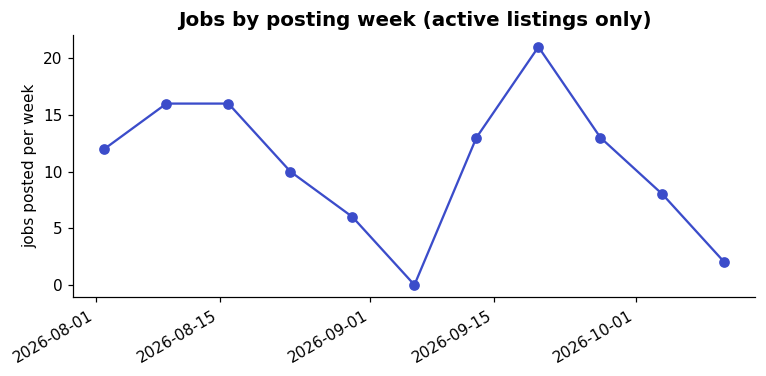

,jobs
posted_date,
2026-08-23,10
2026-08-30,6
2026-09-06,0
2026-09-13,13
2026-09-20,21
2026-09-27,13
2026-10-04,8
2026-10-11,2


In [27]:
weekly = df.set_index("posted_date").resample("W").size()
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(weekly.index, weekly.values, color=ACCENT, marker="o")
ax.set_ylabel("jobs posted per week")
ax.set_title("Jobs by posting week (active listings only)")
fig.autofmt_xdate()
save(fig, "A4_jobs_over_time")
plt.show()
weekly.tail(8).to_frame("jobs")

# Part B - IT deep dive
Only IT jobs from here on.

## B1. Which IT fields are the most requested?

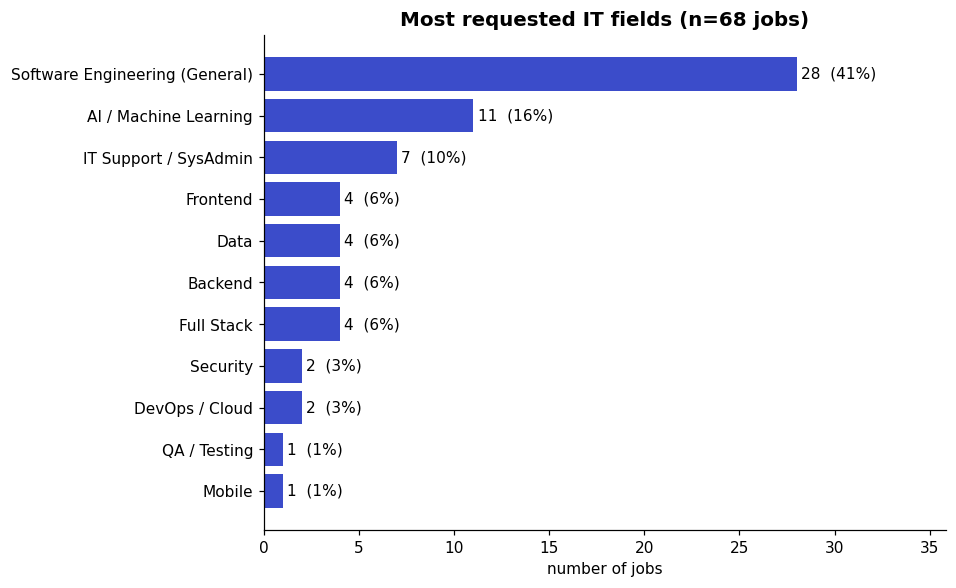

,jobs,% of IT jobs
field,,
Software Engineering (General),28,41.2
AI / Machine Learning,11,16.2
IT Support / SysAdmin,7,10.3
Frontend,4,5.9
Data,4,5.9
Backend,4,5.9
Full Stack,4,5.9
Security,2,2.9
DevOps / Cloud,2,2.9


In [28]:
field_counts = it_jobs["field"].value_counts()
fields = field_counts.index.tolist()
plot_counts(field_counts, f"Most requested IT fields (n={N_IT} jobs)", "B1_it_fields")
pd.DataFrame({"jobs": field_counts, "% of IT jobs": (field_counts / N_IT * 100).round(1)})

## B2. Which IT skills are requested most often?
Share of IT jobs that mention each skill. Bar colour = skill group.

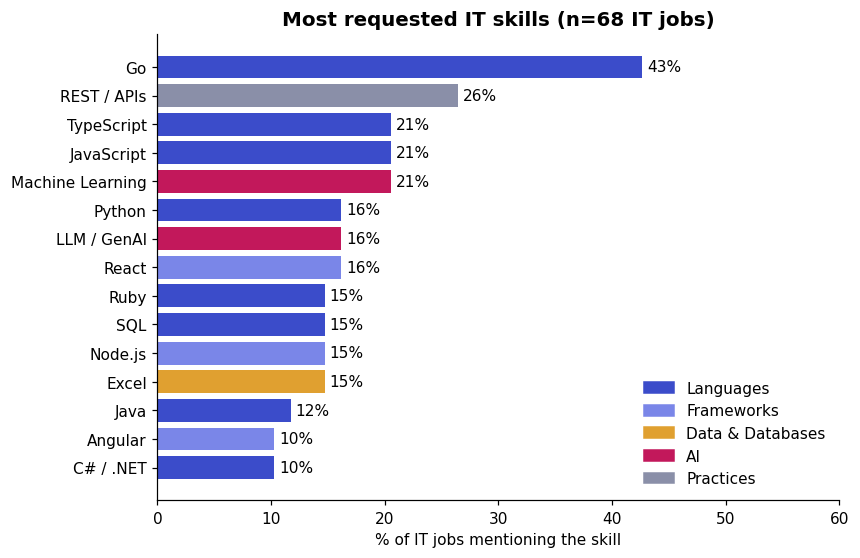

,% of IT jobs mentioning at least one skill of the group
Languages,61.8
Practices,30.9
Data & Databases,25.0
Frameworks,22.1
Cloud & DevOps,22.1
AI,22.1


In [29]:
share = it_jobs[skill_cols].mean() * 100
skill_rank = share.sort_values(ascending=False)
top15 = skill_rank.head(15)[::-1]

fig, ax = plt.subplots(figsize=(8, 5.5))
bars = ax.barh([label(c) for c in top15.index], top15.values, color=[GROUP_COLORS[group(c)] for c in top15.index])
ax.bar_label(bars, labels=[f"{v:.0f}%" for v in top15.values], padding=3)
ax.set_xlim(0, max(60, top15.max() + 10))
ax.set_xlabel("% of IT jobs mentioning the skill")
ax.set_title(f"Most requested IT skills (n={N_IT} IT jobs)")
used = [g for g in GROUP_COLORS if g in {group(c) for c in top15.index}]
ax.legend(handles=[Patch(color=GROUP_COLORS[g], label=g) for g in used], loc="lower right", frameon=False)
save(fig, "B2_top_skills")
plt.show()

by_group = pd.Series({g: it_jobs[[c for c in skill_cols if group(c) == g]].any(axis=1).mean() * 100
                      for g in GROUP_COLORS if any(group(c) == g for c in skill_cols)}).round(1)
by_group.sort_values(ascending=False).to_frame("% of IT jobs mentioning at least one skill of the group")

## B3. What skills does each IT field ask for?
Each cell = % of jobs **in that field** mentioning the skill. Grey rows (`*`) have fewer than 10 jobs, shown for reference only.

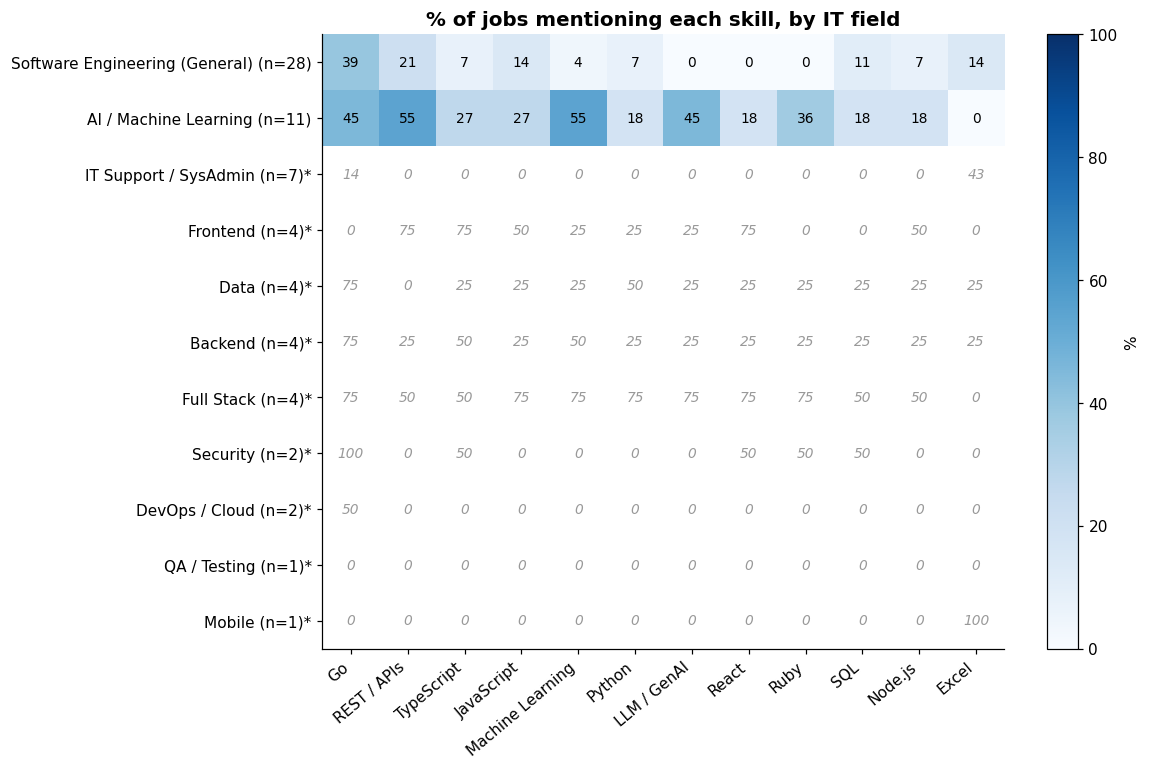

In [30]:
top_cols = skill_rank.head(12).index.tolist()
heat = it_jobs.groupby("field")[top_cols].mean().reindex(fields) * 100
small = (field_counts < MIN_N).reindex(fields).values
shown = np.ma.masked_array(heat.values, mask=np.repeat(small[:, None], heat.shape[1], axis=1))
row_labels = [f"{f} (n={field_counts[f]}){'*' if field_counts[f] < MIN_N else ''}" for f in fields]

fig, ax = plt.subplots(figsize=(10, 1.2 + 0.55 * len(fields)))
im = ax.imshow(shown, cmap="Blues", vmin=0, vmax=100, aspect="auto")
ax.set_xticks(range(len(top_cols)), [label(c) for c in top_cols], rotation=40, ha="right")
ax.set_yticks(range(len(fields)), row_labels)
for i in range(heat.shape[0]):
    for j in range(heat.shape[1]):
        v = heat.values[i, j]
        color = "#999999" if small[i] else ("white" if v > 55 else "black")
        ax.text(j, i, f"{v:.0f}", ha="center", va="center", color=color, fontsize=9, style="italic" if small[i] else "normal")
ax.set_title("% of jobs mentioning each skill, by IT field")
fig.colorbar(im, ax=ax, label="%")
save(fig, "B3_skills_by_it_field")
plt.show()

In [31]:
# the 5 most requested skills of each IT field
rows = {}
for f in fields:
    s = it_jobs.loc[it_jobs["field"] == f, skill_cols].mean().mul(100).sort_values(ascending=False).head(5)
    rows[f] = ", ".join(f"{label(c)} {v:.0f}%" for c, v in s.items() if v > 0)
pd.DataFrame({"jobs": field_counts, "top 5 skills": pd.Series(rows)})

,jobs,top 5 skills
Software Engineering (General),28,"Go 39%, REST / APIs 21%, Excel 14%, JavaScript..."
AI / Machine Learning,11,"Machine Learning 55%, REST / APIs 55%, Go 45%,..."
IT Support / SysAdmin,7,"Excel 43%, Power BI 14%, Azure 14%, Go 14%"
Frontend,4,"React 75%, TypeScript 75%, REST / APIs 75%, Ja..."
Data,4,"Go 75%, Python 50%, React 25%, Power BI 25%, T..."
Backend,4,"Go 75%, TypeScript 50%, Java 50%, C# / .NET 50..."
Full Stack,4,"Python 75%, Ruby 75%, JavaScript 75%, Machine ..."
Security,2,"Go 100%, React 50%, TypeScript 50%, GCP 50%, R..."
DevOps / Cloud,2,"Go 50%, Kubernetes 50%"
QA / Testing,1,


## B4. Seniority by IT field

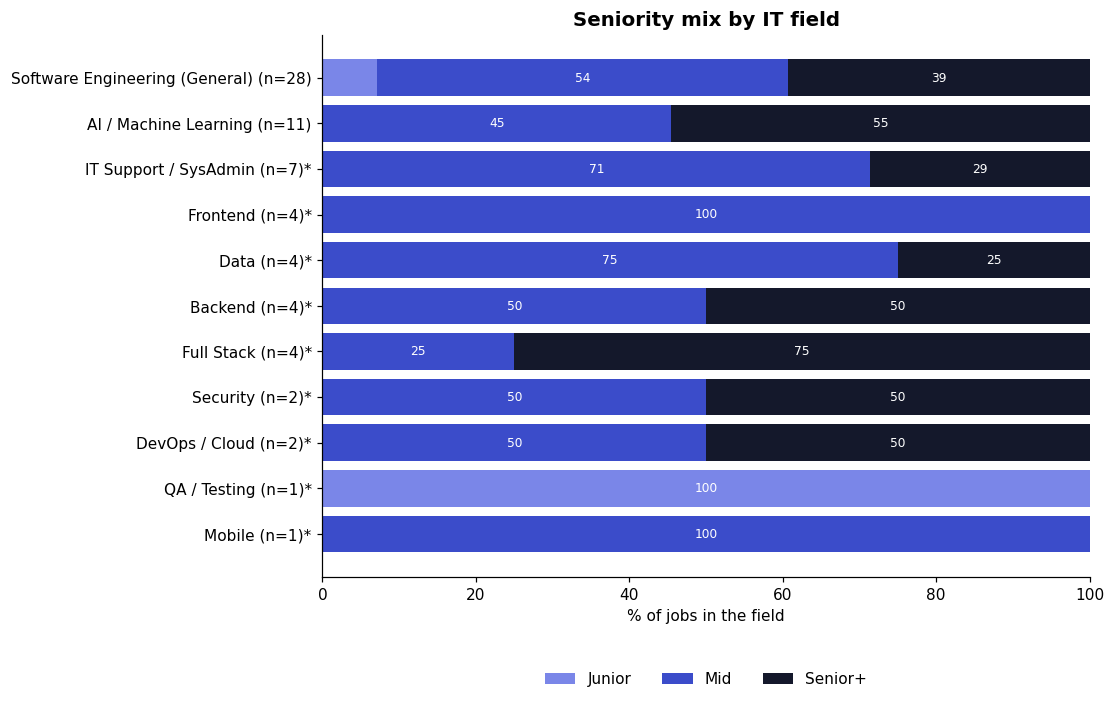

seniority,Junior,Mid,Senior+
field,,,
Software Engineering (General),2,15,11
AI / Machine Learning,0,5,6
IT Support / SysAdmin,0,5,2
Frontend,0,4,0
Data,0,3,1
Backend,0,2,2
Full Stack,0,1,3
Security,0,1,1
DevOps / Cloud,0,1,1


In [32]:
plot_seniority(it_jobs, "field", fields, "Seniority mix by IT field", "B4_seniority_by_it_field")

## B5. Salary by IT field

11 of 68 jobs show a salary (16%)


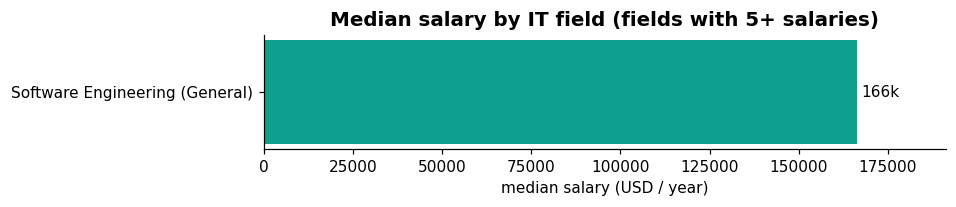

,jobs,median,min,max,note
field,,,,,
Full Stack,1,185000.0,185000.0,185000.0,* too few salaries
Software Engineering (General),6,166250.0,67500.0,320000.0,
Frontend,1,97500.0,97500.0,97500.0,* too few salaries
AI / Machine Learning,3,35000.0,15000.0,200000.0,* too few salaries


In [33]:
salary_summary(it_jobs, "field", f"Median salary by IT field (fields with {MIN_SALARY_N}+ salaries)", "B5_salary_by_it_field")

# Part C - SQL, Tableau and findings

## SQL version of the analysis (SQLite)
The same questions answered with SQL. The tables hold **no job text, company names or links**.

In [34]:
jobs_table = df[["id", "source", "market_field", "field", "is_it_job", "seniority", "location",
                 "posted_date", "salary_min", "salary_max", "salary_mid", "salary_available"]].copy()
jobs_table["posted_date"] = jobs_table["posted_date"].dt.strftime("%Y-%m-%d")

job_skills = (it_jobs.melt(id_vars="id", value_vars=skill_cols, var_name="skill", value_name="required")
              .query("required").drop(columns="required"))
job_skills["skill"] = job_skills["skill"].str.replace("has_", "", regex=False)
job_skills["skill_group"] = job_skills["skill"].map(lambda s: GROUP_OF.get(s, "Other"))

con = sqlite3.connect("../data/clean/jobs.db")
jobs_table.to_sql("jobs", con, if_exists="replace", index=False)
job_skills.to_sql("job_skills", con, if_exists="replace", index=False)

def sql(query):
    return pd.read_sql(query, con)

# 1) most requested fields
sql('''
SELECT market_field, COUNT(*) AS jobs,
       ROUND(100.0 * COUNT(*) / (SELECT COUNT(*) FROM jobs WHERE market_field <> 'Other'), 1) AS pct
FROM jobs WHERE market_field <> 'Other'
GROUP BY market_field ORDER BY jobs DESC
''')

,market_field,jobs,pct
0,IT & Software,68,68.7
1,Sales,7,7.1
2,Operations & Business,5,5.1
3,Marketing,5,5.1
4,Design,4,4.0
5,Customer Support,4,4.0
6,Writing & Content,2,2.0
7,HR & Recruiting,2,2.0
8,Product & Project Management,1,1.0
9,Finance & Legal,1,1.0


In [35]:
# 2) IT jobs vs the rest: size, junior share, average salary
sql('''
SELECT CASE WHEN is_it_job = 1 THEN 'IT' ELSE 'Non-IT' END AS segment,
       COUNT(*) AS jobs,
       ROUND(100.0 * AVG(CASE WHEN seniority = 'Junior' THEN 1 ELSE 0 END), 1) AS junior_pct,
       ROUND(AVG(CASE WHEN salary_available = 1 THEN salary_mid END), 0) AS avg_salary
FROM jobs GROUP BY segment
''')

,segment,jobs,junior_pct,avg_salary
0,IT,68,4.4,142955.0
1,Non-IT,49,6.1,95000.0


In [36]:
# 3) top 10 IT skills
sql('''
SELECT skill, skill_group, COUNT(*) AS jobs,
       ROUND(100.0 * COUNT(*) / (SELECT COUNT(*) FROM jobs WHERE is_it_job = 1), 1) AS pct
FROM job_skills GROUP BY skill, skill_group ORDER BY jobs DESC LIMIT 10
''')

,skill,skill_group,jobs,pct
0,go,Languages,29,42.6
1,rest_api,Practices,18,26.5
2,javascript,Languages,14,20.6
3,machine_learning,AI,14,20.6
4,typescript,Languages,14,20.6
5,llm_genai,AI,11,16.2
6,python,Languages,11,16.2
7,react,Frameworks,11,16.2
8,excel,Data & Databases,10,14.7
9,nodejs,Frameworks,10,14.7


In [37]:
# 4) top 3 skills per IT field (JOIN + window function)
sql('''
WITH counts AS (
    SELECT j.field, s.skill, COUNT(*) AS jobs
    FROM jobs j JOIN job_skills s ON s.id = j.id
    GROUP BY j.field, s.skill
),
ranked AS (
    SELECT field, skill, jobs,
           ROW_NUMBER() OVER (PARTITION BY field ORDER BY jobs DESC) AS rank
    FROM counts
)
SELECT field, rank, skill, jobs FROM ranked WHERE rank <= 3 ORDER BY field, rank
''')

,field,rank,skill,jobs
0,AI / Machine Learning,1,machine_learning,6
1,AI / Machine Learning,2,rest_api,6
2,AI / Machine Learning,3,go,5
3,Backend,1,go,3
4,Backend,2,angular,2
5,Backend,3,csharp_dotnet,2
6,Data,1,go,3
7,Data,2,python,2
8,Data,3,angular,1
9,DevOps / Cloud,1,go,1


In [38]:
# 5) jobs per week
sql('''
SELECT strftime('%Y-W%W', posted_date) AS week, COUNT(*) AS jobs
FROM jobs GROUP BY week ORDER BY week DESC LIMIT 8
''')

,week,jobs
0,2026-W40,2
1,2026-W39,8
2,2026-W38,13
3,2026-W37,21
4,2026-W36,13
5,2026-W34,6
6,2026-W33,10
7,2026-W32,16


## Export for Tableau
Two tables, linked by `id`: all jobs, and the IT skills of the IT jobs. **No company names, job titles, links or descriptions**
are exported, because Tableau Public makes the data public and the sources ask not to republish their listings.

In [39]:
jobs_table.to_csv("../data/clean/jobs_for_tableau.csv", index=False)
job_skills["skill"] = job_skills["skill"].map(lambda s: SKILL_LABELS.get(s, s.replace("_", " ").title()))
job_skills.to_csv("../data/clean/job_skills_for_tableau.csv", index=False)
print("jobs_for_tableau.csv:", jobs_table.shape, "| job_skills_for_tableau.csv:", job_skills.shape)

jobs_for_tableau.csv: (117, 12) | job_skills_for_tableau.csv: (266, 3)


## Key findings (numbers for the README)
Generated from the data. Check each sentence, then rewrite it in your own words.

In [40]:
def pct(col):
    return it_jobs[col].mean() * 100 if col in it_jobs else float("nan")

top_fields = (market_counts / N_KNOWN * 100)
junior_all = (known["seniority"] == "Junior").mean() * 100
junior_it = (it_jobs["seniority"] == "Junior").mean() * 100

print(f"Sample: {N_ALL} remote jobs from {', '.join(sorted(df['source'].dropna().unique()))}.")
print("1. Most requested fields: " + ", ".join(f"{f} ({v:.0f}%)" for f, v in top_fields.head(3).items()) + ".")
print(f"2. IT & Software is {N_IT / N_ALL:.0%} of all jobs in the sample.")
print(f"3. Entry-level (Junior) jobs: {junior_all:.0f}% of all identified jobs, {junior_it:.0f}% of IT jobs.")
print("4. Most requested IT fields: " + ", ".join(f"{f} ({field_counts[f] / N_IT * 100:.0f}%)" for f in fields[:3]) + ".")
print("5. Most requested IT skills: " + ", ".join(f"{label(c)} ({v:.0f}%)" for c, v in skill_rank.head(5).items()) + ".")
print(f"6. Python: {pct('has_python'):.0f}% | JavaScript: {pct('has_javascript'):.0f}% | SQL: {pct('has_sql'):.0f}% | AWS: {pct('has_aws'):.0f}%.")
print()
print("Limits to state in the README: remote jobs only (not the whole market), active listings only, "
      "field and seniority guessed from category/title, salary shown in few postings, skills analysed for IT jobs only.")

Sample: 117 remote jobs from remoteok, remotive.
1. Most requested fields: IT & Software (69%), Sales (7%), Operations & Business (5%).
2. IT & Software is 58% of all jobs in the sample.
3. Entry-level (Junior) jobs: 4% of all identified jobs, 4% of IT jobs.
4. Most requested IT fields: Software Engineering (General) (41%), AI / Machine Learning (16%), IT Support / SysAdmin (10%).
5. Most requested IT skills: Go (43%), REST / APIs (26%), TypeScript (21%), JavaScript (21%), Machine Learning (21%).
6. Python: 16% | JavaScript: 21% | SQL: 15% | AWS: 4%.

Limits to state in the README: remote jobs only (not the whole market), active listings only, field and seniority guessed from category/title, salary shown in few postings, skills analysed for IT jobs only.
